# Market Sentiment from Financial Tweets: Experiments

This notebook documents the development of an NLP model designed to predict market sentiment based on financial tweets. The goal is to implement a classification model that takes tweets as inputs and predicts whether each tweet describes a Bearish (0), Bullish (1), or Neutral (2) market.

This notebook is structured into the following sections:

0. Imports and Setup
1. Data Exploration (including the train/validation split)
2. Data Preprocessing
3. Feature Engineering
4. Classification Models
5. Evaluation and Results

**Beyond the baselines:**
* **Features:** two more transformer encoders, the general-purpose MiniLM and the finance-specific FinTwitBERT.
* **Models:** a decoder LLM (Qwen2.5-0.5B-Instruct) that classifies tweets through few-shot prompting.

## 0. Imports and Setup

In [29]:
import warnings, time, pickle, os, re
warnings.filterwarnings('ignore')

import transformers
transformers.logging.set_verbosity_error()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from tqdm import tqdm

import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score)

from xgboost import XGBClassifier
from gensim.models import Word2Vec

# CPU-only Deep Learning Setup
import torch
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM, pipeline as hf_pipeline

DEVICE, DEVICE_ID = 'cpu', -1
torch.manual_seed(2025)

os.environ["KERAS_BACKEND"] = "torch"
import keras
from keras.models import Model
from keras.layers import LSTM, Dense, Dropout, Bidirectional
from keras.optimizers import Adam as KerasAdam
from keras.metrics import CategoricalAccuracy, F1Score, Precision, Recall
from keras.losses import CategoricalCrossentropy
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from sklearn.model_selection import RandomizedSearchCV, ShuffleSplit

# NLTK resources
for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    try: nltk.download(pkg, quiet=True) 
    except Exception: pass

LABEL_NAMES = ['Bearish (0)', 'Bullish (1)', 'Neutral (2)']
N_LABELS = 3
sentiment_map = {0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}

## 1. Data Exploration

To contextualize the data, an initial exploratory analysis was conducted on the raw training data. This assesses missing values, class distribution, word count distribution, and most frequent words used before any noise reduction techniques are applied. 

The training dataset consists of 9543 observations with no missing values.

In [2]:
df = pd.read_csv('../data/train.csv')

print("Dataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

print(f"\nTotal rows: {len(df)}")
print("\nLabel distribution (counts):")
print(df['label'].value_counts().sort_index())
print("\nLabel distribution (percentage):")
print((df['label'].value_counts(normalize=True).sort_index() * 100).round(2))

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9543 entries, 0 to 9542
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    9543 non-null   object
 1   label   9543 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 149.2+ KB
None

Missing Values
text     0
label    0
dtype: int64

Total rows: 9543

Label distribution (counts):
label
0    1442
1    1923
2    6178
Name: count, dtype: int64

Label distribution (percentage):
label
0    15.11
1    20.15
2    64.74
Name: proportion, dtype: float64


### Manual Tweet Analysis

The tweets are full of context-specific details that are better handled with regular expressions:

- A lot of tweets contain `$` followed by either a ticker symbol (e.g. `$TSLA`) or a monetary amount (e.g. `$1,200` / `$+5%`).

- Some numbers have a `+` or a `-` associated with them, these symbols would have been dropped later on, so we tried to preserve them given the financial context.

- All time related details seemed irrelevant to our problem.

- Links and mentions were found in a huge percentage of the tweets.

- Errors like `optimismÃ¢â‚¬â€what` were found.

All of this directly motivates the custom regex rules in Section 2, which convert these patterns into placeholder tokens (`>stock`, `>cost`, `>positivenum`, `>negativenum`,
`>date`, `>time`, `>link`, `>mention`) instead of deleting them, preserving the signal that something financial is being discussed.

In [3]:
for text in df['text'].head(10):
    print(text)
    print("")

$BYND - JPMorgan reels in expectations on Beyond Meat https://t.co/bd0xbFGjkT

$CCL $RCL - Nomura points to bookings weakness at Carnival and Royal Caribbean https://t.co/yGjpT2ReD3

$CX - Cemex cut at Credit Suisse, J.P. Morgan on weak building outlook https://t.co/KN1g4AWFIb

$ESS: BTIG Research cuts to Neutral https://t.co/MCyfTsXc2N

$FNKO - Funko slides after Piper Jaffray PT cut https://t.co/z37IJmCQzB

$FTI - TechnipFMC downgraded at Berenberg but called Top Pick at Deutsche Bank https://t.co/XKcPDilIuU

$GM - GM loses a bull https://t.co/tdUfG5HbXy

$GM: Deutsche Bank cuts to Hold https://t.co/7Fv1ZiFZBS

$GTT: Cowen cuts to Market Perform

$HNHAF $HNHPD $AAPL - Trendforce cuts iPhone estimate after Foxconn delay https://t.co/rlnEwzlzzS



### Train and Validation Split

We use an 80/20 stratified split so the class proportions are preserved in both sets. (K-Fold cross validation could also be used here as an alternative but this would increase our training time drastically)

In [4]:
train, val = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)
y_train, y_val = train['label'].values, val['label'].values

print(f"Train size: {len(train)}  |  Validation size: {len(val)}")
print(train.head(5))

Train size: 7634  |  Validation size: 1909
                                                   text  label
2186          Nasdaq prices 600M of 0.875% senior notes      2
6819                 Futures up https://t.co/diz7v5lmVb      1
6157  $ECONX: November Nonfarm Private Payrolls 125K...      0
2462  Twitter users explain why Kohl's stock just go...      0
4097  Agilysys : Restaurants Find Sustainable Method...      2


### Class Distribution (Bar Chart)

The dataset is not balanced: Neutral (2) has more entries than the other two classes combined, so accuracy is not a good evaluation metric for our models.

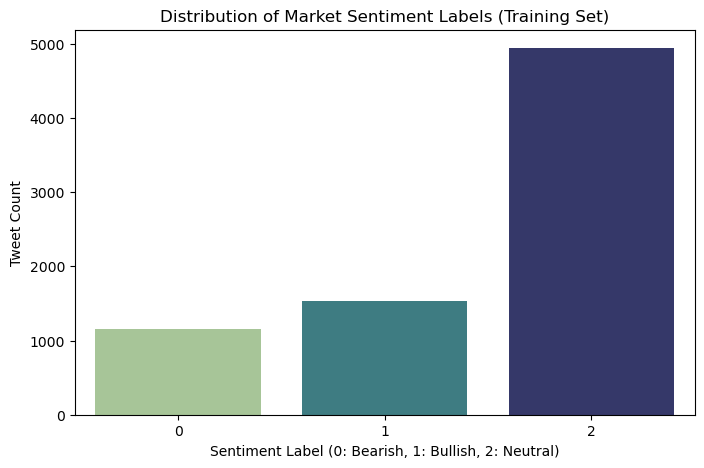

label
0    15.12
1    20.15
2    64.74
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=train, x='label', hue='label', palette='crest', legend=False)
plt.title('Distribution of Market Sentiment Labels (Training Set)')
plt.xlabel('Sentiment Label (0: Bearish, 1: Bullish, 2: Neutral)')
plt.ylabel('Tweet Count')
plt.show()

print(train['label'].value_counts(normalize=True).sort_index().mul(100).round(2))

### Tweet Length Analysis

Word counts per tweet, overall distribution, and the most frequent words before any cleaning.

Word Count (raw tweets):
count    7634.000000
mean       12.191905
std         4.666499
min         1.000000
25%         9.000000
50%        11.000000
75%        15.000000
max        32.000000
Name: word_count, dtype: float64


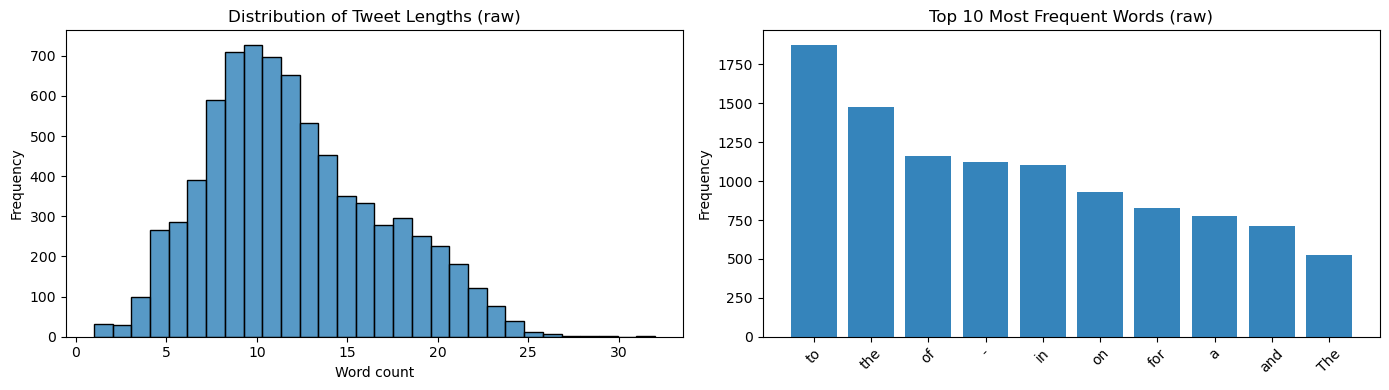


Top 10 most frequent words (raw):
to     1875
the    1475
of     1164
-      1120
in     1103
on      927
for     829
a       778
and     714
The     525
Name: count, dtype: int64


In [6]:
train['word_count'] = train['text'].apply(lambda x: len(str(x).split()))

print('Word Count (raw tweets):')
print(train['word_count'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train['word_count'], bins=30, ax=axes[0])
axes[0].set_title('Distribution of Tweet Lengths (raw)')
axes[0].set_xlabel('Word count')
axes[0].set_ylabel('Frequency')

all_words = ' '.join(train['text'].astype(str)).split()
freq = pd.Series(all_words).value_counts()
top10_raw = freq.head(10)
axes[1].bar(top10_raw.index, top10_raw.values, alpha=0.9)
axes[1].set_title('Top 10 Most Frequent Words (raw)')
axes[1].set_ylabel('Frequency')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("\nTop 10 most frequent words (raw):")
print(top10_raw)

Most tweets are short, which favours models that work well on short text, sparse BoW representations can be very sparse per document, while sentence embedding models (MiniLM, FinTwitBERT) are specifically designed to summarise short passages into a single dense vector.

The top 10 raw words list is dominated by **stopwords** rather than finance specific terms. This is expected and is precisely the noise that Section 2's preprocessing (stop-word removal, and also regex for links and mentions) is designed to remove, so that the informative vocabulary becomes more prominent for the BoW and Word2Vec feature sets.

### Word Clouds per Sentiment

Visualises the most frequent words in each sentiment class before preprocessing.

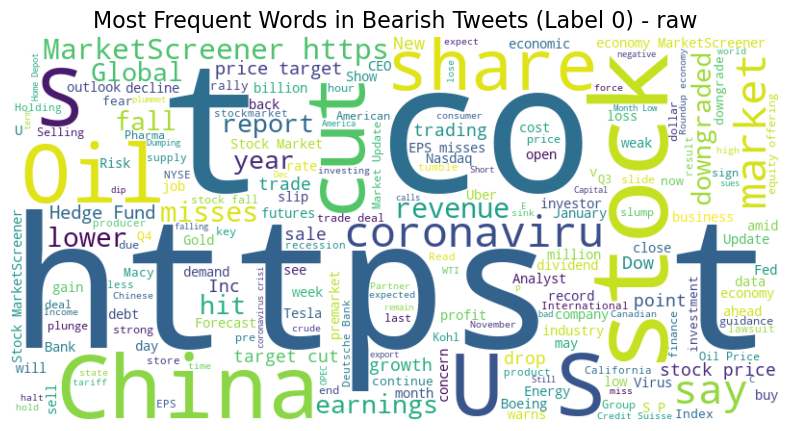

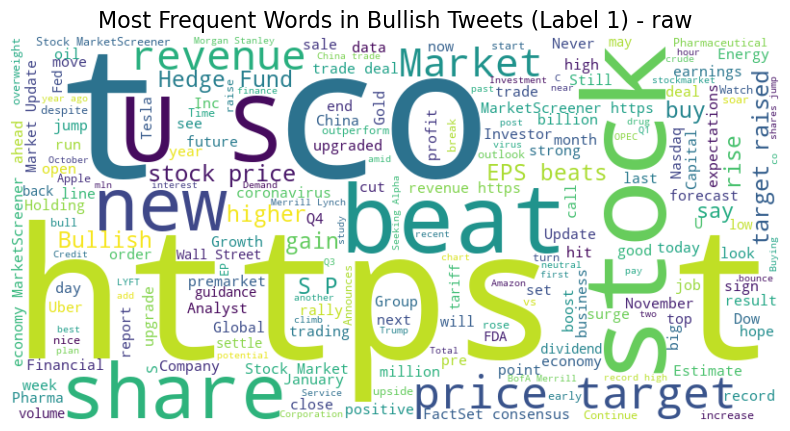

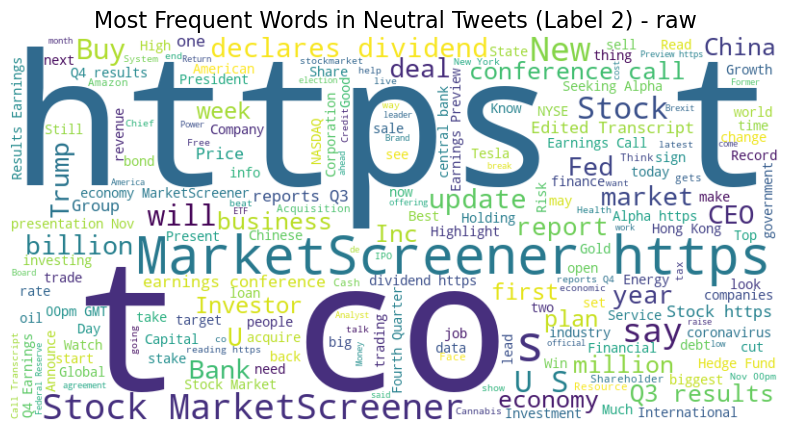

In [7]:
def generate_wordcloud(text_data, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(text_data)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=16)
    plt.axis('off')
    plt.show()

for label, name in sentiment_map.items():
    combined_text = " ".join(train[train['label'] == label]['text'].astype(str))
    generate_wordcloud(combined_text, f'Most Frequent Words in {name} Tweets (Label {label}) - raw')

Even on raw text, some class specific vocabulary is already visible beneath the noise: 
- Bearish tweets surface *"cut"*, *"oil"*,
*"China"*, *"coronavirus"*.
- Bullish tweets tend to surface words like *"new"*,
*"beat"*.
- Neutral tweets are more evenly spread, as expected.

This suggests the lexical signal for sentiment exists and should be learnable, but it is currently diluted by URLs, mentions and stopwords, which is what motivates the cleaning pipeline.

## 2. Data Preprocessing

We implement four preprocessing techniques:

1. **Regular expressions** - normalise URLs, mentions, dates, times, stock tickers, and numbers into semantic placeholder tokens (`>link`, `>mention`, `>date`, `>time`, `>stock`, `>cost`, `>positivenum`, `>negativenum`, `>number`). This both removes noise and preserves the fact that something was mentioned, even after the specific value is taken away.

2. **Lowercasing** – reduces vocabulary size by folding case variants into a single token.

3. **Stop-word removal** – removes high frequency, low information English words (`the`, `a`, `is`, ...) plus a small custom list of domain noise tokens (`https`, `co`, `t`, `rt`, `marketscreener`, `stock`, `market`).

4. **Stemming vs. Lemmatization** – two alternative ways of reducing inflected words to a common base form:
   - *Stemming* is fast and rule-based, but can produce non words.
   - *Lemmatization* is slower but produces real dictionary forms, which can help downstream models that rely on pretrained word vectors expecting real words.

   We build **both** a stemmed and a lemmatized version of the cleaned corpus, and compare their effect on a Logistic Regression + TF-IDF model.

A separate, lighter cleaning function (`clean_tweet_transformer`) is used for transformer encoders because it keeps natural sentence structure (no stop-word removal or stemming/lemmatization) since these models were pretrained on natural language and perform best when given fluent text.

In [8]:
stop_words = set(stopwords.words('english'))
finance_keep_words = {'up', 'down', 'above', 'below', 'over', 'under', 'more', 'most', 'less','no', 'not', 'nor', 'against'}
stop_words = stop_words.difference(finance_keep_words)
custom_noise = {'https', 'co', 't', 'rt', 'marketscreener', 'stock', 'market'}
stop_words = stop_words.union(custom_noise)
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


def _date_url_regex(text):
    """Shared normalisation: stock tags, ASCII cleanup, URLs, dates, mentions, time, $ tickers."""
    text = re.sub(r'\([A-Z]{1,4}\)', '>stock', text)
    text = text.encode("ascii", "ignore").decode()
    text = re.sub(r'http\S+|www\S+|https\S+', '>link', text, flags=re.MULTILINE)

    months = (r"(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may"
              r"|jun(?:e)?|jul(?:y)?|aug(?:ust)?|sep(?:tember|t)?"
              r"|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?)")
    weekdays = (r"(?:mon(?:day)?|tue(?:sday)?|wed(?:nesday)?|thu(?:rsday)?"
                r"|fri(?:day)?|sat(?:urday)?|sun(?:day)?)")

    complex_date = (r'\b(?:' + months +
                    r'\s+\d{1,2}(?:st|nd|rd|th)?(?:,?\s+\d{2,4})?|\d{1,2}(?:st|nd|rd|th)?\s+'
                    + months + r'(?:,?\s+\d{2,4})?)\b')
    text = re.sub(complex_date, '>date', text)
    text = re.sub(r'\b\d+(?:st|nd|rd|th)?\s*(?:days?|weeks?|years?)\b', '>date', text)
    text = re.sub(r'\b(?:' + weekdays + r'|' + months + r')\b', '>date', text)

    text = re.sub(r'@\w+', '>mention', text)
    text = re.sub(r'\b\d{1,2}(?::\d{2})?\s*(?:am|pm)(?:\s+[a-z]{3,4})?\b', '>time', text)
    text = re.sub(r'\$[a-zA-Z]+', '>stock', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def _normalize_numbers(text):
    """Shared numeric normalisation used by both the stemmed and lemmatized pipelines."""
    text = re.sub(r'\+\d+(?:,\d{3})*(?:\.\d+)?k?', '>positivenum', text)
    text = re.sub(r'-\d+(?:,\d{3})*(?:\.\d+)?k?', '>negativenum', text)
    text = re.sub(r'\$\d+(?:,\d{3})*(?:\.\d+)?k?', '>cost', text)
    text = re.sub(r'\b\d+(?:,\d{3})*(?:\.\d+)?k?\b', '>number', text)
    text = re.sub(r'[^\w\s>]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def clean_tweet_advanced(text):
    """Full cleaning with stemming (lowercasing, regex normalisation, stop word removal and stemming)."""
    text = str(text).lower()
    text = _date_url_regex(text)
    text = _normalize_numbers(text)
    words = text.split()
    return ' '.join([stemmer.stem(w) for w in words if w not in stop_words])


def get_wordnet_pos(tag):
    """Map an NLTK POS tag to the format WordNetLemmatizer expects."""
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN


def clean_tweet_lemma(text):
    """Full cleaning with lemmatization (same normalisation, but POS-aware lemmatization instead of stemming)."""
    text = str(text).lower()
    text = _date_url_regex(text)
    text = _normalize_numbers(text)
    words = [w for w in text.split() if w not in stop_words]
    if not words:
        return ''
    tagged = pos_tag(words)
    lemmatized = [lemmatizer.lemmatize(w, get_wordnet_pos(t)) for w, t in tagged]
    return ' '.join(lemmatized)


def clean_tweet_transformer(text):
    """Light cleaning for transformer encoders,to keep natural text structure."""
    text = str(text)
    text = _date_url_regex(text)
    return text

In [9]:
print("Cleaning text")
train_clean = train.copy()
train_clean['text'] = train['text'].apply(clean_tweet_advanced)

val_clean = val.copy()
val_clean['text'] = val['text'].apply(clean_tweet_advanced)

train_clean_lemma = train.copy()
train_clean_lemma['text'] = train['text'].apply(clean_tweet_lemma)

val_clean_lemma = val.copy()
val_clean_lemma['text'] = val['text'].apply(clean_tweet_lemma)

train_clean_tr = train.copy()
train_clean_tr['text'] = train['text'].apply(clean_tweet_transformer)

val_clean_tr = val.copy()
val_clean_tr['text'] = val['text'].apply(clean_tweet_transformer)

print("Before vs After (stemmed - used for BoW / Word2Vec):")
print(train['text'].head())
print(train_clean['text'].head())

print("\nBefore vs After (lemmatized - alternative for BoW comparison):")
print(train['text'].head())
print(train_clean_lemma['text'].head())

print("\nBefore vs After (transformer cleaning):")
print(train['text'].head())
print(train_clean_tr['text'].head())

Cleaning text
Before vs After (stemmed - used for BoW / Word2Vec):
2186            Nasdaq prices 600M of 0.875% senior notes
6819                   Futures up https://t.co/diz7v5lmVb
6157    $ECONX: November Nonfarm Private Payrolls 125K...
2462    Twitter users explain why Kohl's stock just go...
4097    Agilysys : Restaurants Find Sustainable Method...
Name: text, dtype: object
2186                nasdaq price 600m >number senior note
6819                                       futur up >link
6157    >stock >date nonfarm privat payrol >number vs ...
2462    twitter user explain kohl got obliter report e...
4097    agilysi restaur find sustain method limit food...
Name: text, dtype: object

Before vs After (lemmatized - alternative for BoW comparison):
2186            Nasdaq prices 600M of 0.875% senior notes
6819                   Futures up https://t.co/diz7v5lmVb
6157    $ECONX: November Nonfarm Private Payrolls 125K...
2462    Twitter users explain why Kohl's stock just go...
4097 

### Tweet Length Analysis for Cleaned Text

We ran the same word count and frequency analysis on the now cleaned text, so the effect of preprocessing can be compared against the raw text statistics above.

Word Count (cleaned, stemmed tweets):
count    7634.000000
mean        9.094839
std         3.127312
min         0.000000
25%         7.000000
50%         9.000000
75%        11.000000
max        28.000000
Name: word_count, dtype: float64


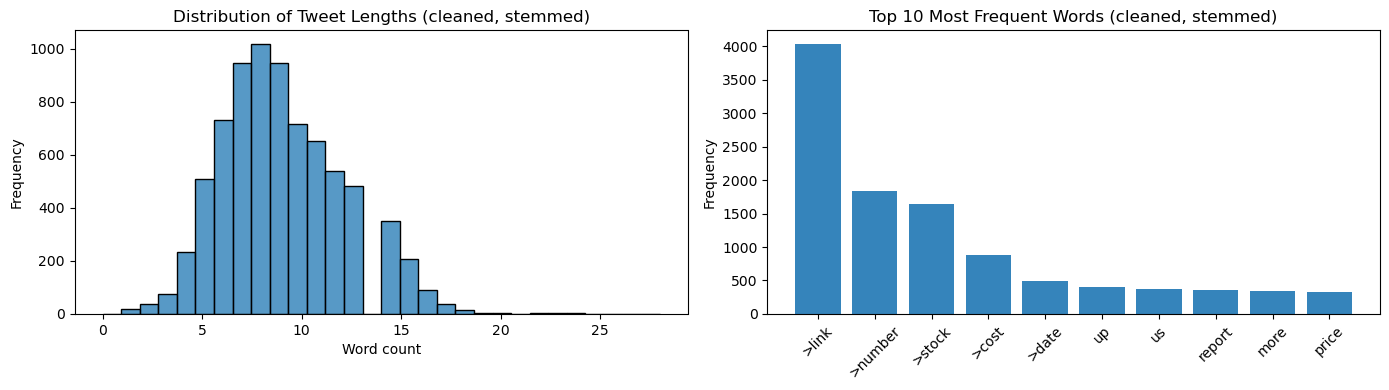


Top 10 most frequent words (cleaned, stemmed):
>link      4038
>number    1839
>stock     1640
>cost       875
>date       499
up          402
us          366
report      353
more        340
price       333
Name: count, dtype: int64


In [10]:
train_clean['word_count'] = train_clean['text'].apply(lambda x: len(str(x).split()))

print('Word Count (cleaned, stemmed tweets):')
print(train_clean['word_count'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train_clean['word_count'], bins=30, ax=axes[0])
axes[0].set_title('Distribution of Tweet Lengths (cleaned, stemmed)')
axes[0].set_xlabel('Word count')
axes[0].set_ylabel('Frequency')

all_words = ' '.join(train_clean['text']).split()
freq = pd.Series(all_words).value_counts()
top10_clean = freq.head(10)
axes[1].bar(top10_clean.index, top10_clean.values, alpha=0.9)
axes[1].set_title('Top 10 Most Frequent Words (cleaned, stemmed)')
axes[1].set_ylabel('Frequency')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("\nTop 10 most frequent words (cleaned, stemmed):")
print(top10_clean)

Compared to the raw top 10 list (dominated by stopwords), the cleaned top 10 is now dominated by placeholder tokens (`>link`, `>number`,`>stock`, `>cost`, `>date`) and a handful of genuinely informative finance words. This confirms that:

- The regex step is correctly normalising URLs/tickers/numbers (their placeholder tokens are now among the most frequent words).

- Stop word removal has successfully removed stop words from the top of the frequency list.

- The average tweet is noticeably shorter in word count after cleaning, since stopwords are dropped entirely.

### Word Clouds per Sentiment for Cleaned Text

Same word clouds as before, now on the cleaned text and without showing the ">" tags.

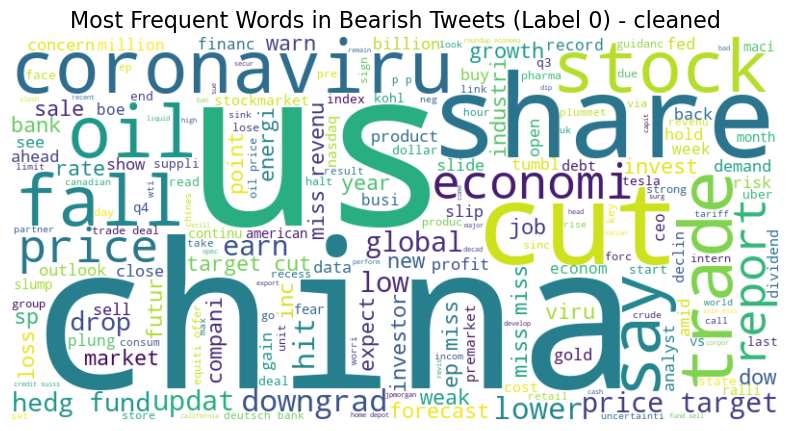

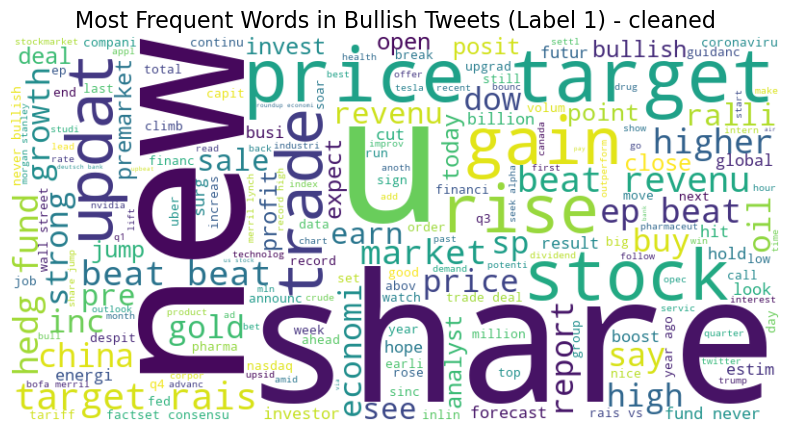

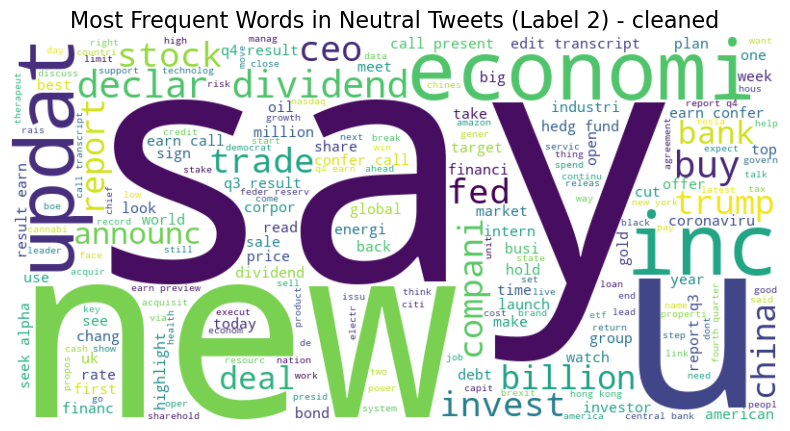

In [11]:
for label, name in sentiment_map.items():
    combined_text = " ".join(train_clean[train_clean['label'] == label]['text'].astype(str))
    
    filtered_words = [word for word in combined_text.split() if not word.startswith('>')]
    filtered_text = " ".join(filtered_words)

    generate_wordcloud(filtered_text, f'Most Frequent Words in {name} Tweets (Label {label}) - cleaned')

After cleaning, the sentiment bearing words are much more visible:
- Bearish word clouds are now clearly led by negative words like *"cut"*, *"fall"*.

- Bullish by positive words like *"rise"*, *"gain"*.

- Neutral remains a mix.

## 3. Feature Engineering

Three baseline feature representations are built:
- **BoW (TF-IDF)** on the stemmed text (with a **lemmatized** variant built in parallel for the comparison).
- **Word2Vec** averaged embeddings on the stemmed text.
- **Transformer Encoder** – CLS embeddings from `distilbert-base-uncased`, a general-purpose English encoder.

Two further transformer encoders:
- **MiniLM** (`all-MiniLM-L6-v2`) – a general-purpose sentence transformer.
- **FinTwitBERT** – an encoder trained on financial tweets.

### 3.1 BoW (TF-IDF) – Stemmed

Includes a visualisation of the top 20 features by average TF-IDF score, to check which words dominate the vector space.

Extracting BoW Features (TF-IDF, stemmed)
TF-IDF (stemmed) Training Shape: (7634, 5000)
TF-IDF (stemmed) Validation Shape: (1909, 5000)



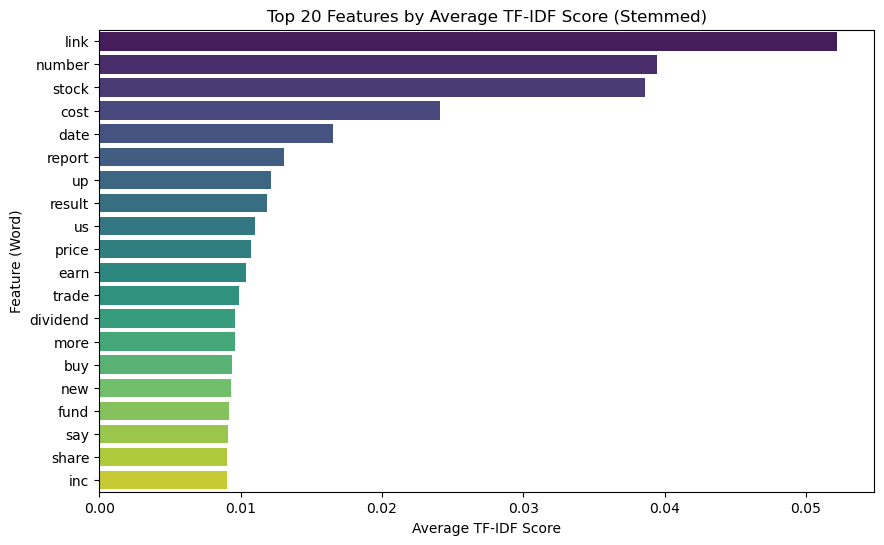

In [12]:
print("Extracting BoW Features (TF-IDF, stemmed)")
tfidf = TfidfVectorizer(max_features=5000)
X_train_bow = tfidf.fit_transform(train_clean['text'])
X_val_bow = tfidf.transform(val_clean['text'])

print(f"TF-IDF (stemmed) Training Shape: {X_train_bow.shape}")
print(f"TF-IDF (stemmed) Validation Shape: {X_val_bow.shape}\n")

avg_tfidf = np.asarray(X_train_bow.mean(axis=0)).ravel()
feature_names = np.array(tfidf.get_feature_names_out())

top_indices = avg_tfidf.argsort()[-20:][::-1]
top_features = feature_names[top_indices]
top_scores = avg_tfidf[top_indices]

plt.figure(figsize=(10, 6))
sns.barplot(x=top_scores, y=top_features, palette='viridis')
plt.title('Top 20 Features by Average TF-IDF Score (Stemmed)')
plt.xlabel('Average TF-IDF Score')
plt.ylabel('Feature (Word)')
plt.show()

The highest average-TF-IDF features are a mix of **placeholder tokens** (which appear in almost every tweet) and **finance-specific terms** ( *"report"*, *"result"*, *"price"*). 

Because TF-IDF down weights terms that appear in every document, a very high frequency placeholder like `>link` having a high score (rather than being suppressed) suggests it still varies enough in frequency across tweets to carry some discriminative signal and is worth keeping rather than adding to the stop word list.

### 3.1b BoW (TF-IDF) – Lemmatized (for comparison)

Extracting BoW Features (TF-IDF, lemmatized)
TF-IDF (lemmatized) Training Shape: (7634, 5000)
TF-IDF (lemmatized) Validation Shape: (1909, 5000)

Vocabulary size - stemmed:    5000
Vocabulary size - lemmatized: 5000


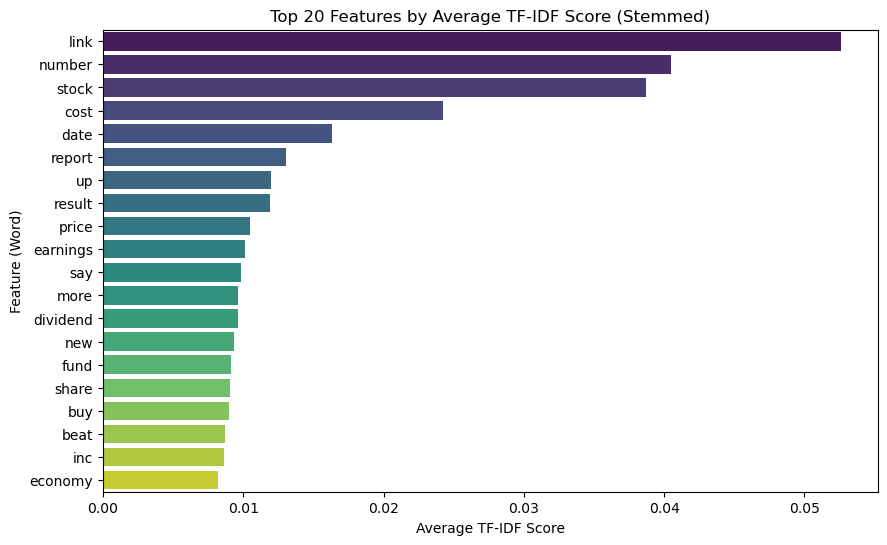

In [13]:
print("Extracting BoW Features (TF-IDF, lemmatized)")
tfidf_lemma = TfidfVectorizer(max_features=5000)
X_train_bow_lemma = tfidf_lemma.fit_transform(train_clean_lemma['text'])
X_val_bow_lemma = tfidf_lemma.transform(val_clean_lemma['text'])

print(f"TF-IDF (lemmatized) Training Shape: {X_train_bow_lemma.shape}")
print(f"TF-IDF (lemmatized) Validation Shape: {X_val_bow_lemma.shape}")
print(f"\nVocabulary size - stemmed:    {len(tfidf.vocabulary_)}")
print(f"Vocabulary size - lemmatized: {len(tfidf_lemma.vocabulary_)}")

avg_tfidf = np.asarray(X_train_bow_lemma.mean(axis=0)).ravel()
feature_names = np.array(tfidf_lemma.get_feature_names_out())

top_indices = avg_tfidf.argsort()[-20:][::-1]
top_features = feature_names[top_indices]
top_scores = avg_tfidf[top_indices]

plt.figure(figsize=(10, 6))
sns.barplot(x=top_scores, y=top_features, palette='viridis')
plt.title('Top 20 Features by Average TF-IDF Score (Stemmed)')
plt.xlabel('Average TF-IDF Score')
plt.ylabel('Feature (Word)')
plt.show()

As expected the top words look slightly different.

### 3.2 Word2Vec

In [14]:
train_tokens = [str(t).split() for t in train_clean['text']]
val_tokens = [str(t).split() for t in val_clean['text']]
w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4)


def avg_w2v(tokens, model, size=100):
    valid = [w for w in tokens if w in model.wv.key_to_index]
    return np.mean(model.wv[valid], axis=0) if valid else np.zeros(size)


X_train_w2v = np.array([avg_w2v(t, w2v_model) for t in train_tokens])
X_val_w2v = np.array([avg_w2v(t, w2v_model) for t in val_tokens])

print(f"Word2Vec Training Shape: {X_train_w2v.shape}")
print(f"Word2Vec Validation Shape: {X_val_w2v.shape}")

Word2Vec Training Shape: (7634, 100)
Word2Vec Validation Shape: (1909, 100)


Word2Vec is trained from scratch on our training data, so embedding quality depends heavily on how often each word appears. Placeholder tokens (`>stock`, `>link`, etc.) appear very frequently and should get well trained vectors, while rare finance words may get noisy ones. This is the main reason we also use pretrained sentence transformer embeddings (MiniLM / FinTwitBERT) below, since they bring general language and finance domain knowledge that a from scratch Word2Vec on ~7.6k short documents cannot.

### 3.3 Transformer Encoder (DistilBERT CLS Embeddings)

Using DistilBERT we load `distilbert-base-uncased` with a `feature-extraction` pipeline and take the `[CLS]` token embedding for each tweet.

Lightly cleaned text (`clean_tweet_transformer`) is used, since this encoder (like MiniLM and FinTwitBERT below) was pretrained on natural language and performs best on fluent text rather than stemmed or stopword stripped tokens.


In [15]:
print("Encoding with Base DistilBERT")


DISTILBERT_CKPT = "distilbert-base-uncased"
db_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_CKPT)
db_model = AutoModel.from_pretrained(DISTILBERT_CKPT)
db_model.eval()


def encode_cls_batched(texts, tokenizer, model, batch_size=32, max_len=128, desc="Encoding"):
    """
    Batched CLS token embedding extraction vectorised over batches for speed.
    Returns a numpy array of shape (n_texts, hidden_size).
    """
    all_cls = []
    for i in tqdm(range(0, len(texts), batch_size), desc=desc):
        batch = texts[i: i + batch_size]
        enc = tokenizer(batch, truncation=True, padding=True, max_length=max_len, return_tensors='pt')
        with torch.no_grad():
            out = model(**enc)
        cls_vecs = out.last_hidden_state[:, 0, :].cpu().numpy()
        all_cls.append(cls_vecs)
    return np.vstack(all_cls)


X_train_distilbert = encode_cls_batched(
    train_clean_tr['text'].tolist(), db_tokenizer, db_model,
    batch_size=32, desc="Base DistilBERT CLS - train"
)
X_val_distilbert = encode_cls_batched(
    val_clean_tr['text'].tolist(), db_tokenizer, db_model,
    batch_size=32, desc="Base DistilBERT CLS - val"
)

print(f"Base DistilBERT CLS Training Shape: {X_train_distilbert.shape}")
print(f"Base DistilBERT CLS Validation Shape: {X_val_distilbert.shape}")

Encoding with Base DistilBERT


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Base DistilBERT CLS Training Shape: (7634, 768)
Base DistilBERT CLS Validation Shape: (1909, 768)


### 3.4 Transformer Encoder: MiniLM

A general-purpose sentence transformer (`all-MiniLM-L6-v2`).

In [16]:
print("Encoding with MiniLM")
minilm = SentenceTransformer('all-MiniLM-L6-v2')
X_train_transformer = minilm.encode(train_clean_tr['text'].tolist(), batch_size=64, show_progress_bar=True)
X_val_transformer = minilm.encode(val_clean_tr['text'].tolist(), batch_size=64, show_progress_bar=True)

print(f"MiniLM Training Shape: {X_train_transformer.shape}")
print(f"MiniLM Validation Shape: {X_val_transformer.shape}")

Encoding with MiniLM


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/120 [00:00<?, ?it/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

MiniLM Training Shape: (7634, 384)
MiniLM Validation Shape: (1909, 384)


### 3.5 Transformer Encoder: FinTwitBERT

A transformer encoder trained on financial tweets, so it already knows the domain's vocabulary.

In [17]:
print("\nFinTwitBERT sentiment CLS embeddings")
FINTWITBERT_PATH = "StephanAkkerman/FinTwitBERT-sentiment"

ftb_tokenizer = AutoTokenizer.from_pretrained(FINTWITBERT_PATH)
ftb_model = AutoModel.from_pretrained(FINTWITBERT_PATH)
ftb_model.eval()

def encode_batched(texts, tokenizer, model, batch_size=32,max_len=128, desc="Encoding"):
    """
    Tokenize and encode texts in batches. 
    Returns a numpy array of CLS token embeddings, shape (n_texts, hidden_size).
    """
    all_cls = []
    for i in tqdm(range(0, len(texts), batch_size), desc=desc):
        batch = texts[i: i + batch_size]
        enc = tokenizer(batch, truncation=True, padding=True, max_length=max_len, return_tensors='pt')
        with torch.no_grad():
            out = model(**enc)
        cls_vecs = out.last_hidden_state[:, 0, :].cpu().numpy()
        all_cls.append(cls_vecs)
    return np.vstack(all_cls)

X_train_ftb = encode_batched(
    train_clean_tr['text'].tolist(), ftb_tokenizer, ftb_model,
    batch_size=32, desc="FinTwitBERT - train"
)
X_val_ftb = encode_batched(
    val_clean_tr['text'].tolist(), ftb_tokenizer, ftb_model,
    batch_size=32, desc="FinTwitBERT - val"
)
print(f"  FinTwitBERT train: {X_train_ftb.shape}")
print(f"  FinTwitBERT val  : {X_val_ftb.shape}")


FinTwitBERT sentiment CLS embeddings


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  FinTwitBERT train: (7634, 768)
  FinTwitBERT val  : (1909, 768)


We now have three Transformer Encoder feature sets, ranging from general to finance specific:

- **DistilBERT** – general English, faster and lighter than BERT.
- **MiniLM** – general-purpose sentence embeddings.
- **FinTwitBERT** – pretrained specifically on financial tweets.

We would expect F1, for the same simple classifier, to roughly follow this ordering:

**FinTwitBERT > MiniLM > DistilBERT**


## 4. Classification Models

Evaluation helpers first, then traditional ML models (KNN, Logistic Regression, Random Forest, MLP, XGBoost), the lemmatization vs stemming comparison, followed by the Transformer Encoder classifiers (LSTM + zero-shot), and the decoder-LLM classifier.

In [18]:
results_log = []


def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec_w = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec_w = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_w = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)

    print(f"\n{'-' * 55}")
    print(f"  {name}")
    print(f"{'-' * 55}")
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0))
    print(f"  Macro F1: {f1_macro:.4f}")

    return dict(Model=name, Accuracy=acc, Precision_W=prec_w, Recall_W=rec_w, F1_Weighted=f1_w, F1_Macro=f1_macro)


def plot_confusion(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('True'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()


def run_model(label, clf, X_tr, X_v, y_tr, y_v, needs_dense=False):
    if needs_dense:
        X_tr = X_tr.toarray() if hasattr(X_tr, 'toarray') else X_tr
        X_v = X_v.toarray() if hasattr(X_v, 'toarray') else X_v
    t0 = time.time()
    clf.fit(X_tr, y_tr)
    elapsed = time.time() - t0
    y_pred = clf.predict(X_v)
    row = evaluate_model(label, y_v, y_pred)
    row['Train_time_s'] = round(elapsed, 2)
    results_log.append(row)
    plot_confusion(label, y_v, y_pred)
    return clf, y_pred

### 4.1 KNN


KNN

-------------------------------------------------------
  KNN k=11  |  TF-IDF (Stemmed)
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.61      0.34      0.43       288
 Bullish (1)       0.62      0.43      0.51       385
 Neutral (2)       0.77      0.92      0.84      1236

    accuracy                           0.73      1909
   macro avg       0.67      0.56      0.59      1909
weighted avg       0.71      0.73      0.71      1909

  Macro F1: 0.5920


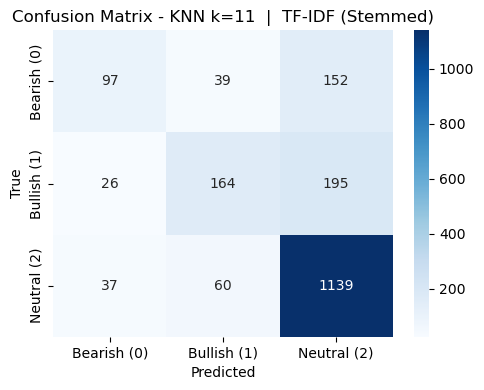


-------------------------------------------------------
  KNN k=11  |  DistilBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.53      0.35      0.42       288
 Bullish (1)       0.56      0.49      0.52       385
 Neutral (2)       0.81      0.91      0.86      1236

    accuracy                           0.74      1909
   macro avg       0.64      0.58      0.60      1909
weighted avg       0.72      0.74      0.73      1909

  Macro F1: 0.6022


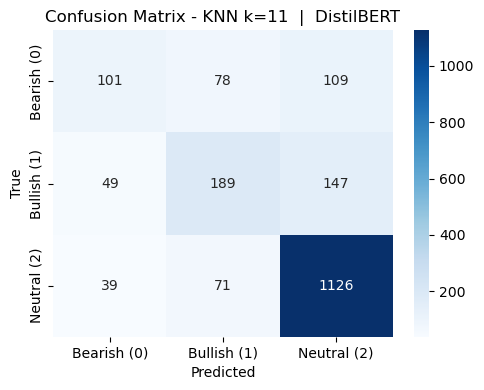


-------------------------------------------------------
  KNN k=11  |  MiniLM
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.58      0.38      0.46       288
 Bullish (1)       0.66      0.56      0.60       385
 Neutral (2)       0.82      0.92      0.86      1236

    accuracy                           0.77      1909
   macro avg       0.68      0.62      0.64      1909
weighted avg       0.75      0.77      0.75      1909

  Macro F1: 0.6427


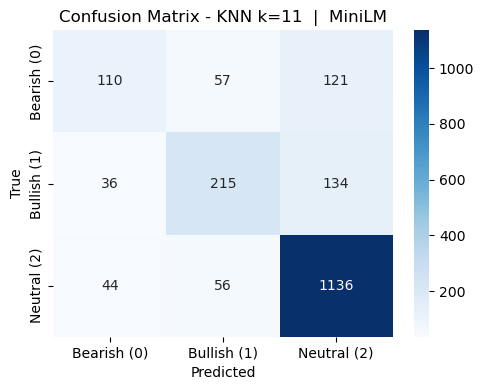


-------------------------------------------------------
  KNN k=11  |  FinTwitBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.78      0.88      0.83       288
 Bullish (1)       0.83      0.82      0.83       385
 Neutral (2)       0.94      0.91      0.92      1236

    accuracy                           0.89      1909
   macro avg       0.85      0.87      0.86      1909
weighted avg       0.89      0.89      0.89      1909

  Macro F1: 0.8604


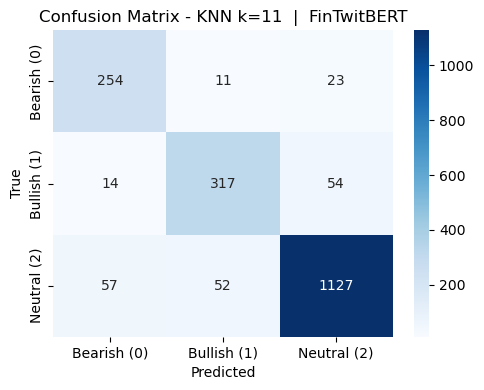

(Pipeline(steps=[('sc', StandardScaler()),
                 ('knn',
                  KNeighborsClassifier(metric='cosine', n_jobs=-1,
                                       n_neighbors=11))]),
 array([2, 2, 1, ..., 1, 0, 2]))

In [19]:
print("\nKNN")
run_model("KNN k=11  |  TF-IDF (Stemmed)",
          Pipeline([('sc', StandardScaler(with_mean=False)), ('knn', KNeighborsClassifier(n_neighbors=11, metric='cosine', n_jobs=-1))]),
          X_train_bow, X_val_bow, y_train, y_val)


run_model("KNN k=11  |  DistilBERT",
        Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=11, metric='cosine', n_jobs=-1))]),
        X_train_distilbert, X_val_distilbert, y_train, y_val)

run_model("KNN k=11  |  MiniLM",
          Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=11, metric='cosine', n_jobs=-1))]),
          X_train_transformer, X_val_transformer, y_train, y_val)


run_model("KNN k=11  |  FinTwitBERT",
            Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=11, metric='cosine', n_jobs=-1))]),
            X_train_ftb, X_val_ftb, y_train, y_val)

### 4.2 Logistic Regression

This is also where we run the stemming vs. lemmatization comparison.


Logistic Regression

-------------------------------------------------------
  LogReg C=5  |  TF-IDF (Stemmed)
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.75      0.51      0.61       288
 Bullish (1)       0.79      0.64      0.71       385
 Neutral (2)       0.83      0.94      0.88      1236

    accuracy                           0.81      1909
   macro avg       0.79      0.70      0.73      1909
weighted avg       0.81      0.81      0.80      1909

  Macro F1: 0.7325


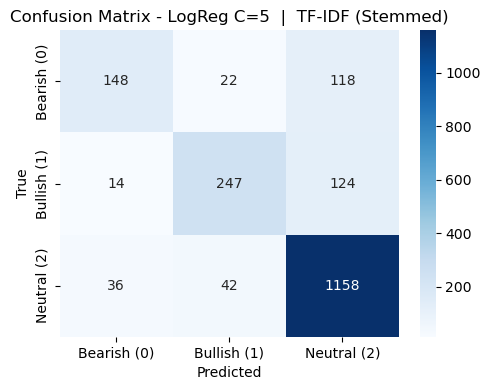


-------------------------------------------------------
  LogReg C=3  |  TF-IDF (Lemmatized)
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.73      0.49      0.59       288
 Bullish (1)       0.77      0.62      0.69       385
 Neutral (2)       0.82      0.93      0.87      1236

    accuracy                           0.80      1909
   macro avg       0.77      0.68      0.72      1909
weighted avg       0.80      0.80      0.79      1909

  Macro F1: 0.7157


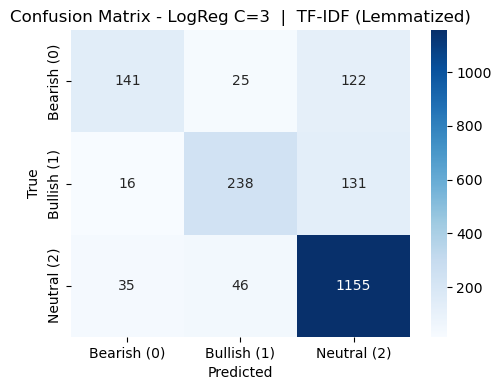


-------------------------------------------------------
  LogReg C=5  |  DistilBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.63      0.52      0.57       288
 Bullish (1)       0.68      0.62      0.65       385
 Neutral (2)       0.83      0.89      0.86      1236

    accuracy                           0.78      1909
   macro avg       0.71      0.67      0.69      1909
weighted avg       0.77      0.78      0.77      1909

  Macro F1: 0.6912


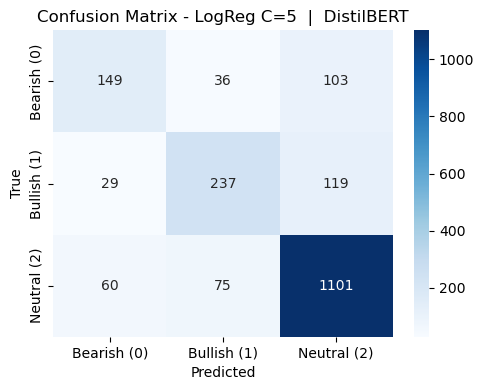


-------------------------------------------------------
  LogReg C=5  |  MiniLM
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.70      0.53      0.60       288
 Bullish (1)       0.70      0.59      0.65       385
 Neutral (2)       0.83      0.92      0.87      1236

    accuracy                           0.79      1909
   macro avg       0.74      0.68      0.71      1909
weighted avg       0.79      0.79      0.79      1909

  Macro F1: 0.7069


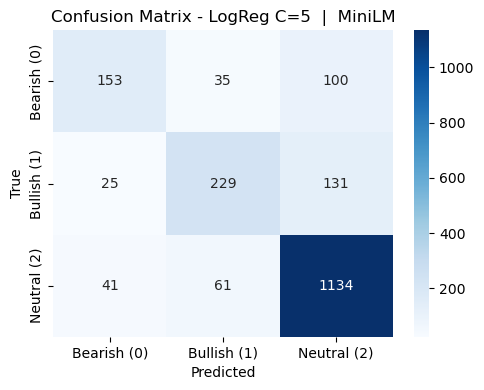


-------------------------------------------------------
  LogReg C=3  |  Word2Vec
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.00      0.00      0.00       288
 Bullish (1)       0.55      0.16      0.24       385
 Neutral (2)       0.67      0.98      0.80      1236

    accuracy                           0.66      1909
   macro avg       0.41      0.38      0.35      1909
weighted avg       0.55      0.66      0.56      1909

  Macro F1: 0.3465


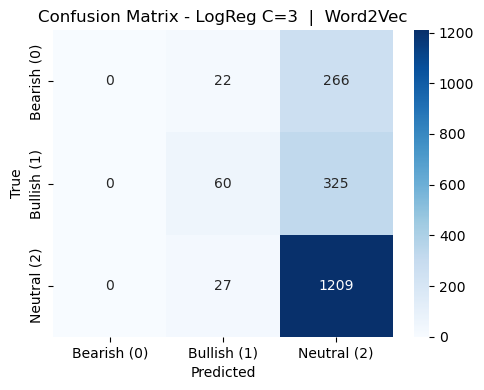


-------------------------------------------------------
  LogReg C=5  |  FinTwitBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.76      0.82      0.78       288
 Bullish (1)       0.81      0.78      0.79       385
 Neutral (2)       0.91      0.91      0.91      1236

    accuracy                           0.87      1909
   macro avg       0.83      0.83      0.83      1909
weighted avg       0.87      0.87      0.87      1909

  Macro F1: 0.8303


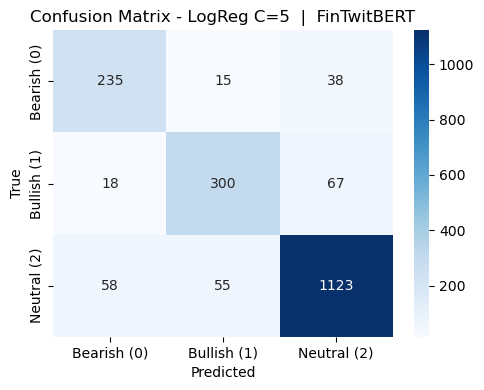

(LogisticRegression(C=5, max_iter=1000, n_jobs=-1),
 array([2, 0, 1, ..., 2, 2, 2]))

In [20]:
print("\nLogistic Regression")
run_model("LogReg C=5  |  TF-IDF (Stemmed)",
          LogisticRegression(C=3, max_iter=1000, solver='lbfgs', n_jobs=-1),
          X_train_bow, X_val_bow, y_train, y_val)

run_model("LogReg C=3  |  TF-IDF (Lemmatized)",
          LogisticRegression(C=3, max_iter=1000, solver='lbfgs', n_jobs=-1),
          X_train_bow_lemma, X_val_bow_lemma, y_train, y_val)

run_model("LogReg C=5  |  DistilBERT",
            LogisticRegression(C=5, max_iter=1000, solver='lbfgs', n_jobs=-1),
            X_train_distilbert, X_val_distilbert, y_train, y_val)

run_model("LogReg C=5  |  MiniLM",
          LogisticRegression(C=5, max_iter=1000, solver='lbfgs', n_jobs=-1),
          X_train_transformer, X_val_transformer, y_train, y_val)

run_model("LogReg C=3  |  Word2Vec",
          LogisticRegression(C=3, max_iter=1000, solver='lbfgs', n_jobs=-1),
          X_train_w2v, X_val_w2v, y_train, y_val)

run_model("LogReg C=5  |  FinTwitBERT",
            LogisticRegression(C=5, max_iter=1000, solver='lbfgs', n_jobs=-1),
            X_train_ftb, X_val_ftb, y_train, y_val)

For this task, the extra dictionary correctness of lemmatization doesn't translate into better separability, so stemming is good enough and is cheaper to compute.

### 4.3 Random Forest


Random Forest

-------------------------------------------------------
  RandomForest n=200  |  TF-IDF (Stemmed)
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.83      0.44      0.58       288
 Bullish (1)       0.80      0.64      0.71       385
 Neutral (2)       0.81      0.95      0.88      1236

    accuracy                           0.81      1909
   macro avg       0.81      0.68      0.72      1909
weighted avg       0.81      0.81      0.80      1909

  Macro F1: 0.7221


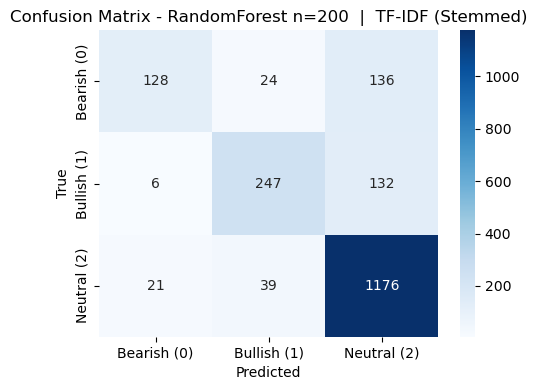


-------------------------------------------------------
  RandomForest n=200  |  MiniLM
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.92      0.12      0.21       288
 Bullish (1)       0.78      0.28      0.42       385
 Neutral (2)       0.71      0.99      0.82      1236

    accuracy                           0.72      1909
   macro avg       0.80      0.46      0.48      1909
weighted avg       0.75      0.72      0.65      1909

  Macro F1: 0.4846


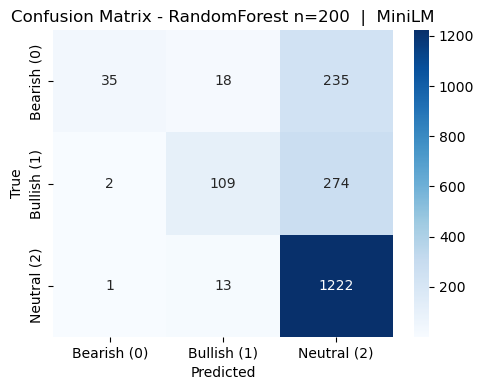


-------------------------------------------------------
  RandomForest n=200  |  FinTwitBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.87      0.78      0.82       288
 Bullish (1)       0.89      0.74      0.81       385
 Neutral (2)       0.89      0.96      0.92      1236

    accuracy                           0.89      1909
   macro avg       0.88      0.83      0.85      1909
weighted avg       0.89      0.89      0.88      1909

  Macro F1: 0.8503


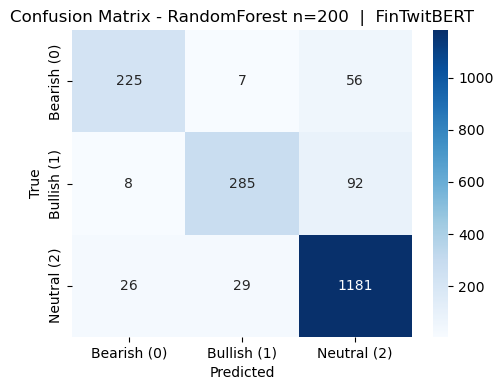

(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
 array([2, 2, 1, ..., 1, 2, 2]))

In [21]:
print("\nRandom Forest")
run_model("RandomForest n=200  |  TF-IDF (Stemmed)",
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        X_train_bow, X_val_bow, y_train, y_val, needs_dense=True)

run_model("RandomForest n=200  |  MiniLM",
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        X_train_transformer, X_val_transformer, y_train, y_val)


run_model("RandomForest n=200  |  FinTwitBERT",
        RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        X_train_ftb, X_val_ftb, y_train, y_val)

### 4.4 MLP


MLP

-------------------------------------------------------
  MLP (512,256,128) relu  |  TF-IDF (Stemmed)
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.67      0.52      0.59       288
 Bullish (1)       0.72      0.71      0.71       385
 Neutral (2)       0.85      0.89      0.87      1236

    accuracy                           0.80      1909
   macro avg       0.74      0.71      0.72      1909
weighted avg       0.79      0.80      0.79      1909

  Macro F1: 0.7225


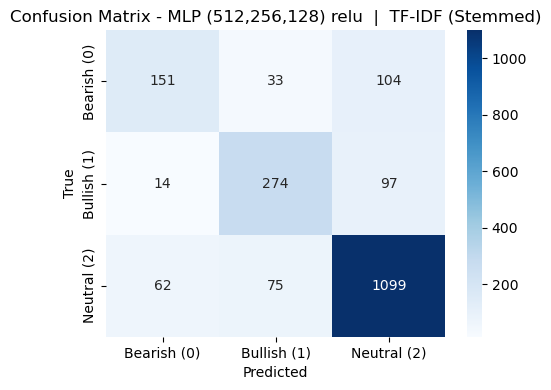


-------------------------------------------------------
  MLP (512,256,128) relu  |  MiniLM
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.71      0.54      0.61       288
 Bullish (1)       0.71      0.62      0.66       385
 Neutral (2)       0.84      0.92      0.88      1236

    accuracy                           0.80      1909
   macro avg       0.75      0.69      0.72      1909
weighted avg       0.79      0.80      0.79      1909

  Macro F1: 0.7175


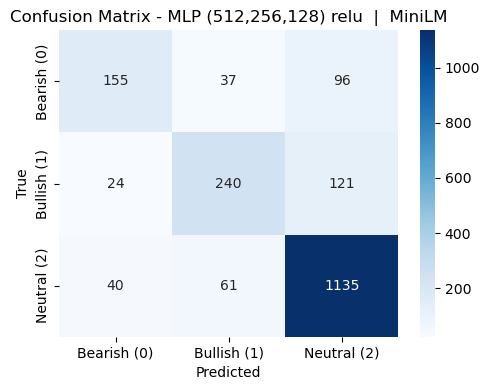


-------------------------------------------------------
  MLP (512,256,128) relu  |  FinTwitBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.83      0.83      0.83       288
 Bullish (1)       0.86      0.80      0.83       385
 Neutral (2)       0.92      0.94      0.93      1236

    accuracy                           0.89      1909
   macro avg       0.87      0.85      0.86      1909
weighted avg       0.89      0.89      0.89      1909

  Macro F1: 0.8612


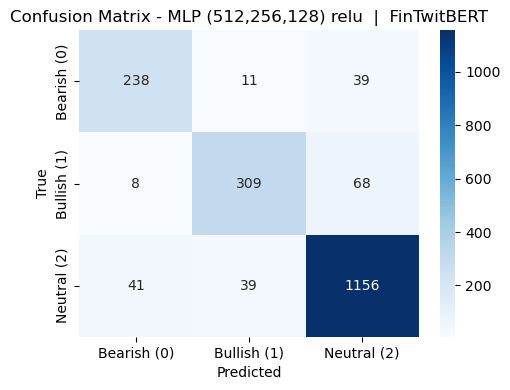

(MLPClassifier(early_stopping=True, hidden_layer_sizes=(512, 256, 128),
               max_iter=300, random_state=42),
 array([2, 2, 1, ..., 1, 0, 2]))

In [22]:
print("\nMLP")
run_model("MLP (512,256,128) relu  |  TF-IDF (Stemmed)",
          MLPClassifier(hidden_layer_sizes=(512, 256, 128), activation='relu', max_iter=200, random_state=42, early_stopping=True, validation_fraction=0.1),
          X_train_bow, X_val_bow, y_train, y_val, needs_dense=True)

run_model("MLP (512,256,128) relu  |  MiniLM",
          MLPClassifier(hidden_layer_sizes=(512, 256, 128), activation='relu', max_iter=300, random_state=42, early_stopping=True, validation_fraction=0.1),
          X_train_transformer, X_val_transformer, y_train, y_val)


run_model("MLP (512,256,128) relu  |  FinTwitBERT",
            MLPClassifier(hidden_layer_sizes=(512, 256, 128), activation='relu', max_iter=300, random_state=42, early_stopping=True, validation_fraction=0.1),
            X_train_ftb, X_val_ftb, y_train, y_val)

### 4.5 XGBoost


 XGBoost

-------------------------------------------------------
  XGBoost |  TF-IDF (Stemmed)
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.83      0.45      0.59       288
 Bullish (1)       0.83      0.55      0.66       385
 Neutral (2)       0.80      0.97      0.88      1236

    accuracy                           0.81      1909
   macro avg       0.82      0.66      0.71      1909
weighted avg       0.81      0.81      0.79      1909

  Macro F1: 0.7089


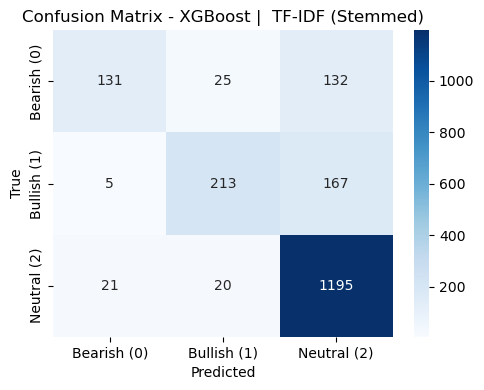


-------------------------------------------------------
  XGBoost |  MiniLM
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.81      0.39      0.52       288
 Bullish (1)       0.76      0.54      0.63       385
 Neutral (2)       0.79      0.96      0.87      1236

    accuracy                           0.79      1909
   macro avg       0.79      0.63      0.68      1909
weighted avg       0.79      0.79      0.77      1909

  Macro F1: 0.6754


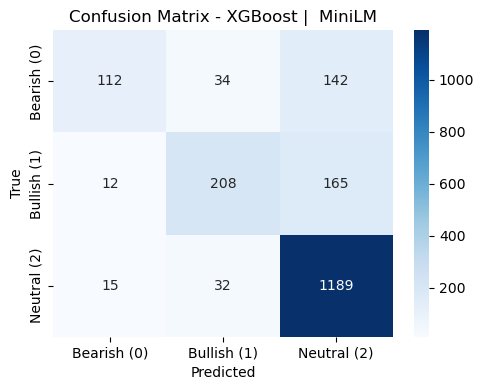


-------------------------------------------------------
  XGBoost |  FinTwitBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.84      0.83      0.84       288
 Bullish (1)       0.88      0.79      0.84       385
 Neutral (2)       0.91      0.95      0.93      1236

    accuracy                           0.90      1909
   macro avg       0.88      0.86      0.87      1909
weighted avg       0.90      0.90      0.90      1909

  Macro F1: 0.8669


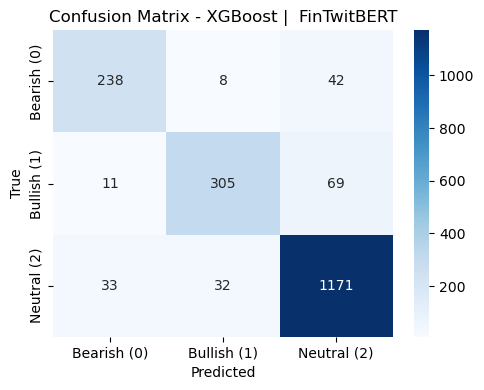

(XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.8, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='mlogloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=0.05, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=7, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=300, n_jobs=-1,
               num_parallel_tree=None, ...),
 array([2, 2, 1, ..., 1, 2, 2]))

In [23]:
print("\n XGBoost")
run_model("XGBoost |  TF-IDF (Stemmed)",
            XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42, n_jobs=-1),
            X_train_bow, X_val_bow, y_train, y_val, needs_dense=True)

run_model("XGBoost |  MiniLM",
            XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42, n_jobs=-1),
            X_train_transformer, X_val_transformer, y_train, y_val)


run_model("XGBoost |  FinTwitBERT",
            XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42, n_jobs=-1),
            X_train_ftb, X_val_ftb, y_train, y_val)

### 4.6 LSTM on FinTwitBERT CLS Embeddings


LSTM on FinTwitBERT CLS embeddings
Epoch 1/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8807 - f1_score: 0.8455 - loss: 0.3208 - precision: 0.8976 - recall: 0.8604 - val_accuracy: 0.8832 - val_f1_score: 0.8439 - val_loss: 0.2958 - val_precision: 0.8919 - val_recall: 0.8774 - learning_rate: 0.0010
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8998 - f1_score: 0.8692 - loss: 0.2615 - precision: 0.9088 - recall: 0.8913 - val_accuracy: 0.8958 - val_f1_score: 0.8662 - val_loss: 0.2677 - val_precision: 0.9019 - val_recall: 0.8910 - learning_rate: 0.0010
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9095 - f1_score: 0.8822 - loss: 0.2311 - precision: 0.9182 - recall: 0.8999 - val_accuracy: 0.9047 - val_f1_score: 0.8820 - val_loss: 0.2715 - val_precision: 0.9091 - val_recall: 0.8910 - learning_rate: 0.0010
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9176 - f1_score: 0.8922 - loss: 0.2153 - precision: 0.9256 - recal

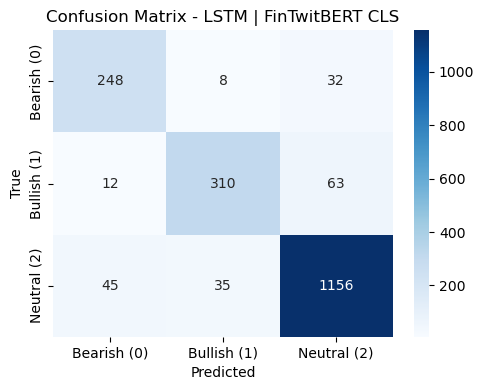

In [24]:
lstm_val_preds = None

print("\nLSTM on FinTwitBERT CLS embeddings")

y_train_ohe = to_categorical(y_train)
y_val_ohe = to_categorical(y_val)

class LSTMClassifier(Model):
    """
    Bidirectional LSTM head on a frozen CLS embedding vector.
    The (embedding_dim,) vector is reshaped to (1, embedding_dim) so
    the LSTM treats it as a single-timestep sequence.
    """
    def __init__(self, input_dim, lstm_units=128, dropout_rate=0.3, num_classes=3):
        super().__init__()
        self.reshape = keras.layers.Reshape((1, input_dim))
        self.lstm = Bidirectional(LSTM(units=lstm_units, return_sequences=False), name='bilstm')
        self.dropout = Dropout(rate=dropout_rate)
        self.dense = Dense(64, activation='relu')
        self.out = Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = self.reshape(inputs)
        x = self.lstm(x)
        x = self.dropout(x, training=training)
        x = self.dense(x)
        return self.out(x)

input_dim = X_train_ftb.shape[1]
lstm_model = LSTMClassifier(input_dim, lstm_units=128, dropout_rate=0.3)
lstm_model.compile(
    optimizer=KerasAdam(learning_rate=0.001, weight_decay=0.01),
    loss=CategoricalCrossentropy(),
    metrics=[
        CategoricalAccuracy(name="accuracy"),
        Precision(name="precision"),
        Recall(name="recall"),
        F1Score(average="macro", name="f1_score"),
    ]
)

t0 = time.time()
lstm_model.fit(
    X_train_ftb, y_train_ohe,
    validation_data=(X_val_ftb, y_val_ohe),
    epochs=15,
    batch_size=64,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1),
    ],
    verbose=1
)
print(f"LSTM training time: {round(time.time() - t0, 1)} s")

lstm_val_preds = np.argmax(lstm_model.predict(X_val_ftb, batch_size=64), axis=1)

row_lstm = evaluate_model("LSTM  |  FinTwitBERT CLS", y_val, lstm_val_preds)
row_lstm['Train_time_s'] = round(time.time() - t0, 2)
results_log.append(row_lstm)
plot_confusion("LSTM | FinTwitBERT CLS", y_val, lstm_val_preds)

### 4.7 FinTwitBERT Zero-Shot Classifier

Uses the model's built in sentiment analysis head.


 FinTwitBERT zero-shot


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot val inference: 50.0 s

-------------------------------------------------------
  FinTwitBERT zero-shot
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.69      0.92      0.79       288
 Bullish (1)       0.69      0.83      0.75       385
 Neutral (2)       0.94      0.80      0.86      1236

    accuracy                           0.83      1909
   macro avg       0.77      0.85      0.80      1909
weighted avg       0.85      0.83      0.83      1909

  Macro F1: 0.8026


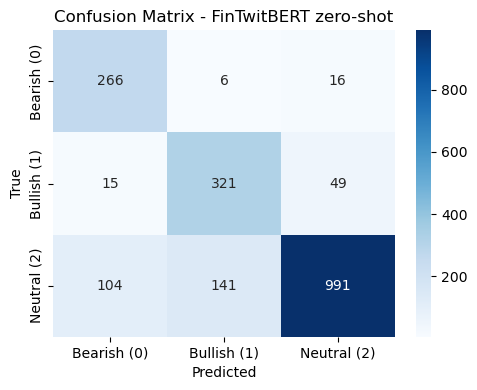

In [25]:
zs_val_preds = None


print("\n FinTwitBERT zero-shot")

fintwitbert_clf = hf_pipeline(
    "sentiment-analysis",
    model=FINTWITBERT_PATH,
    device=DEVICE_ID,
    batch_size=64,
    truncation=True
)
LABEL_MAP = {'BEARISH': 0, 'BULLISH': 1, 'NEUTRAL': 2}

def classify_batched(texts, clf, desc="Classifying"):
    """
    Run the sentiment analysis pipeline over texts in batches.
    Returns (predictions array, probabilities array).
    """
    preds, probas = [], []
    batch_size = 64
    for i in tqdm(range(0, len(texts), batch_size), desc=desc):
        batch = texts[i: i + batch_size]
        outputs = clf(batch, top_k=None)

        for result in outputs:
            if isinstance(result, dict):
                result = [result]

            top = max(result, key=lambda x: x['score'])
            lbl = LABEL_MAP[top['label']]

            scores = {e['label']: e['score'] for e in result}
            prob = [
                scores.get('BEARISH', 0.0),
                scores.get('BULLISH', 0.0),
                scores.get('NEUTRAL', 0.0)
            ]

            preds.append(lbl)
            probas.append(prob)

    return np.array(preds), np.array(probas)

t0 = time.time()
zs_val_preds, _ = classify_batched(
    val['text'].tolist(), fintwitbert_clf, desc="FinTwitBERT ZS - val"
)
print(f"Zero-shot val inference: {round(time.time() - t0, 1)} s")

row_zs = evaluate_model("FinTwitBERT zero-shot", y_val, zs_val_preds)
row_zs['Train_time_s'] = 'N/A'
results_log.append(row_zs)
plot_confusion("FinTwitBERT zero-shot", y_val, zs_val_preds)

### 4.8 Decoder Classifier (Few-Shot LLM)

We use **Qwen2.5-0.5B-Instruct**, a small, instruction-tuned, decoder-only causal language model. For each tweet, we build a few-shot prompt containing three labelled examples (one per class) plus the chat template, and ask the model to output a single sentiment word. Generation is batched (`max_new_tokens=4`) and the output is parsed back into {0, 1, 2}.

Because CPU generation is slow, we evaluate on a random subsample of the validation set.


[EXTRA] Decoder classification (Qwen2.5-0.5B-Instruct)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Using the following training tweets for the few-shot prompt:
[Bearish] Stock Market Update: NAHB Housing Market Index ticks down in November
[Bullish] Hedge Funds Have Never Been This Bullish On Diamond Hill Investment Group, Inc. >stock
[Neutral] U.S. Treasury Secretary Steven Mnuchin says G-7 counterparts and central bankers vow to do "whatever is necessary" >link
--------------------------------------------------------------------------------



Decoder classification time for 150 tweets: 466.1 s

-------------------------------------------------------
  Decoder (Qwen2.5-0.5B-Instruct) few-shot | n=150
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       1.00      0.05      0.09        21
 Bullish (1)       0.26      0.90      0.41        31
 Neutral (2)       0.90      0.39      0.54        98

    accuracy                           0.45       150
   macro avg       0.72      0.45      0.35       150
weighted avg       0.79      0.45      0.45       150

  Macro F1: 0.3465


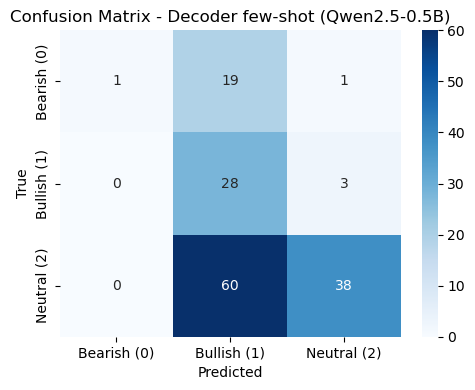

In [26]:
print("\n[EXTRA] Decoder classification (Qwen2.5-0.5B-Instruct)")

DECODER_MODEL_PATH = "Qwen/Qwen2.5-0.5B-Instruct"

dec_tokenizer = AutoTokenizer.from_pretrained(DECODER_MODEL_PATH)
dec_model = AutoModelForCausalLM.from_pretrained(DECODER_MODEL_PATH)
dec_model.eval()

# Left-padding is required for correct batched generation
dec_tokenizer.padding_side = 'left'
if dec_tokenizer.pad_token is None:
    dec_tokenizer.pad_token = dec_tokenizer.eos_token

# Few-shot sampling
# Sample exactly one of each class from the training set to avoid data leakage
bearish_example = train_clean_tr[train_clean_tr['label'] == 0].sample(1, random_state=42)['text'].iloc[0]
bullish_example = train_clean_tr[train_clean_tr['label'] == 1].sample(1, random_state=42)['text'].iloc[0]
neutral_example = train_clean_tr[train_clean_tr['label'] == 2].sample(1, random_state=42)['text'].iloc[0]

FEW_SHOT_EXAMPLES = [
    (bearish_example, "Bearish"),
    (bullish_example, "Bullish"),
    (neutral_example, "Neutral")
]

print("Using the following training tweets for the few-shot prompt:")
for txt, lbl in FEW_SHOT_EXAMPLES:
    print(f"[{lbl}] {txt}")
print("-" * 80)

DECODER_LABEL_TO_ID = {'bearish': 0, 'bullish': 1, 'neutral': 2}

def build_decoder_prompt(tweet):
    examples_text = "\n".join(
        f'Tweet: "{t}"\nSentiment: {s}' for t, s in FEW_SHOT_EXAMPLES
    )
    instruction = (
        "You are a financial sentiment classifier. Classify each tweet as exactly one of: Bearish, Bullish, or Neutral. "
        "Respond with only that single word.\n\n"
        f"{examples_text}\n\n"
        f'Tweet: "{tweet}"\nSentiment:'
    )
    messages = [{"role": "user", "content": instruction}]
    return dec_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

def decoder_classify_batched(texts, batch_size=8, max_new_tokens=4, desc="Decoder classification"):
    """
    Returns an array of predicted label ids (0/1/2). Falls back to 2 (Neutral) if the generated text cannot be parsed.
    """
    preds = []
    for i in tqdm(range(0, len(texts), batch_size), desc=desc):
        batch_texts = texts[i: i + batch_size]
        prompts = [build_decoder_prompt(t) for t in batch_texts]
        enc = dec_tokenizer(prompts, return_tensors='pt', padding=True, truncation=True, max_length=512)
        with torch.no_grad():
            out = dec_model.generate(
                **enc,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=dec_tokenizer.pad_token_id,
            )
        input_len = enc['input_ids'].shape[1]
        for j in range(len(batch_texts)):
            gen_tokens = out[j][input_len:]
            gen_text = dec_tokenizer.decode(gen_tokens, skip_special_tokens=True).strip().lower()

            label = None
            for word, idx in DECODER_LABEL_TO_ID.items():
                if word in gen_text:
                    label = idx
                    break
            if label is None:
                label = 2  # default to Neutral if unparseable

            preds.append(label)
    return np.array(preds)

DECODER_SAMPLE_SIZE = min(150, len(val))
decoder_sample = val.sample(n=DECODER_SAMPLE_SIZE, random_state=42)

t0 = time.time()
decoder_preds = decoder_classify_batched(decoder_sample['text'].tolist())
elapsed = time.time() - t0
print(f"\nDecoder classification time for {DECODER_SAMPLE_SIZE} tweets: {round(elapsed, 1)} s")

row_decoder = evaluate_model(
    f"Decoder (Qwen2.5-0.5B-Instruct) few-shot | n={DECODER_SAMPLE_SIZE}",
    decoder_sample['label'].values, decoder_preds
)
row_decoder['Train_time_s'] = 'N/A'
results_log.append(row_decoder)
plot_confusion("Decoder few-shot (Qwen2.5-0.5B)", decoder_sample['label'].values, decoder_preds)

This model scored poorly. With CPU-only hardware we could only prompt a very small model on a small sample, so this result says more about our resources than about decoder models in general.

## 5. Evaluation and Results

Compares all models trained above using Accuracy, Precision, Recall, Weighted F1 and Macro F1, sorted by Macro F1 (a fair metric given the 3 class imbalanced setup). 

                                           Model  Accuracy  Precision_W  Recall_W  F1_Weighted  F1_Macro Train_time_s
                        LSTM  |  FinTwitBERT CLS    0.8979       0.8981    0.8979       0.8975    0.8687        22.21
                          XGBoost |  FinTwitBERT    0.8979       0.8970    0.8979       0.8967    0.8669        49.87
          MLP (512,256,128) relu  |  FinTwitBERT    0.8921       0.8913    0.8921       0.8914    0.8612         5.09
                        KNN k=11  |  FinTwitBERT    0.8895       0.8922    0.8895       0.8903    0.8604         0.06
              RandomForest n=200  |  FinTwitBERT    0.8858       0.8855    0.8858       0.8832    0.8503         4.85
                      LogReg C=5  |  FinTwitBERT    0.8685       0.8696    0.8685       0.8688    0.8303        11.99
                           FinTwitBERT zero-shot    0.8266       0.8502    0.8266       0.8309    0.8026          N/A
                 LogReg C=5  |  TF-IDF (Stemmed)    0.81

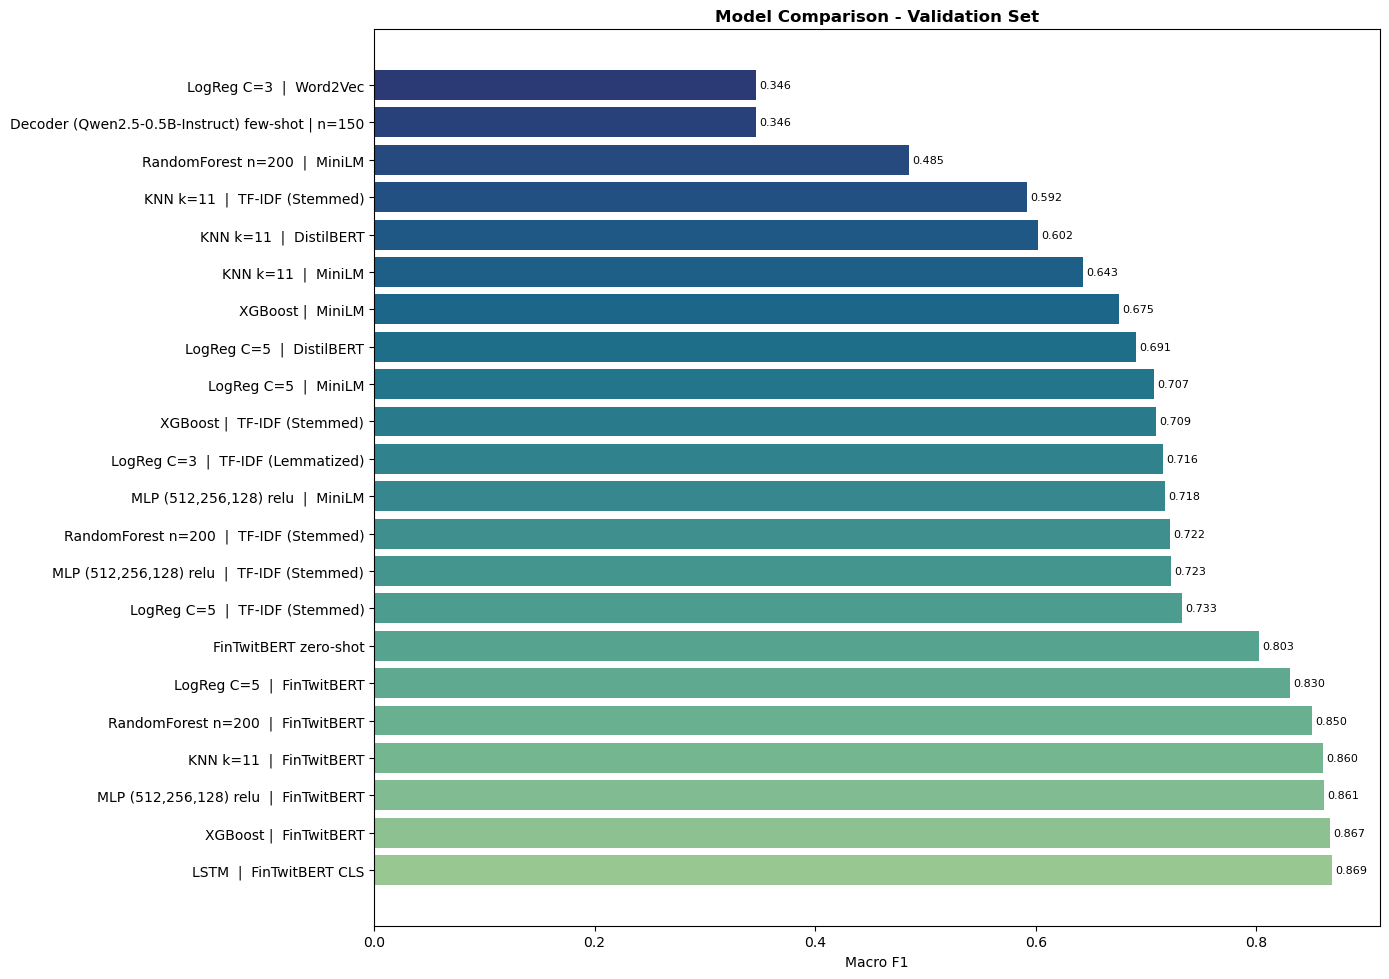

In [27]:
results_df = pd.DataFrame(results_log)
results_df = results_df.sort_values('F1_Macro', ascending=False).reset_index(drop=True)
for col in ['Accuracy', 'Precision_W', 'Recall_W', 'F1_Weighted', 'F1_Macro']:
    results_df[col] = results_df[col].apply(lambda x: round(x, 4) if isinstance(x, float) else x)
print(results_df.to_string(index=False))

plt.figure(figsize=(14, max(5, len(results_df) * 0.45)))
colors = sns.color_palette('crest', len(results_df))
plt.barh(results_df['Model'], results_df['F1_Macro'], color=colors)
for i, v in enumerate(results_df['F1_Macro']):
    if isinstance(v, float):
        plt.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8)
plt.xlabel('Macro F1')
plt.title('Model Comparison - Validation Set', fontweight='bold')
plt.tight_layout()
plt.show()

### Overall Model Comparison & Conclusions


- **Best models**: the LSTM and XGBoost on FinTwitBERT CLS embeddings were almost tied (macro-F1 0.869 and 0.867), with three more models within 0.01. We carried XGBoost forward to hyperparameter tuning.
- **Representation matters most**: every classifier did far better on FinTwitBERT embeddings than on TF-IDF, Word2Vec or general-purpose encoders.
- **Stemming vs. lemmatization**: in our test, lemmatization performed slightly worse than stemming.

### Hyperparameter tuning

Tunes XGBoost on FinTwitBERT embeddings with a randomized search, scored by macro-F1.

Best model: XGBoost deep  |  FinTwitBERT
Hyperparameter tuning XGBoost on FinTwitBERT CLS embeddings
Fitting 1 folds for each of 25 candidates, totalling 25 fits
Hyperparameter search time: 891.9 s

Best params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 1.0}
Best CV Macro F1: 0.8753

-------------------------------------------------------
  XGBoost (tuned)  |  FinTwitBERT
-------------------------------------------------------
              precision    recall  f1-score   support

 Bearish (0)       0.85      0.82      0.84       288
 Bullish (1)       0.89      0.79      0.83       385
 Neutral (2)       0.91      0.95      0.93      1236

    accuracy                           0.90      1909
   macro avg       0.88      0.85      0.87      1909
weighted avg       0.90      0.90      0.90      1909

  Macro F1: 0.8664


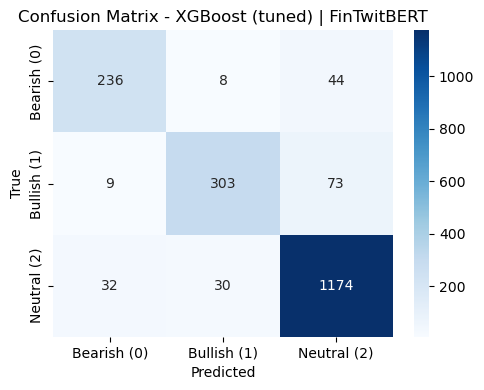

Saved best_model_pipeline.pkl


In [31]:
best_name = "XGBoost deep  |  FinTwitBERT"
feat_label = 'FinTwitBERT'
print(f"Best model: {best_name}")
print("Hyperparameter tuning XGBoost on FinTwitBERT CLS embeddings")

param_dist = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.5],
}

xgb_base = XGBClassifier(eval_metric='mlogloss', random_state=42, n_jobs=1)

search = RandomizedSearchCV(
    xgb_base,
    param_distributions=param_dist,
    n_iter=25,
    scoring='f1_macro',
    cv=ShuffleSplit(n_splits=1, test_size=0.2, random_state=42),
    random_state=42,
    verbose=1,
    n_jobs=-1
)

t0 = time.time()
search.fit(X_train_ftb, y_train)
print(f"Hyperparameter search time: {round(time.time() - t0, 1)} s")

print("\nBest params:", search.best_params_)
print(f"Best CV Macro F1: {search.best_score_:.4f}")

best_clf = search.best_estimator_

val_preds = best_clf.predict(X_val_ftb)
row_tuned = evaluate_model("XGBoost (tuned)  |  FinTwitBERT", y_val, val_preds)
plot_confusion("XGBoost (tuned) | FinTwitBERT", y_val, val_preds)

with open('best_model_pipeline.pkl', 'wb') as f:
    pickle.dump({
        'classifier': best_clf,
        'feature_set': feat_label,
        'best_model_name': best_name,
        'best_params': search.best_params_
    }, f)
print("Saved best_model_pipeline.pkl")

### Test Set Predictions

Generates predictions for `test.csv` using the tuned model.

In [33]:
test_df = pd.read_csv('../data/test.csv')
test_df['text_clean_tr'] = test_df['text'].apply(clean_tweet_transformer)

print(f"Generating test predictions with the tuned model ({best_name})...")

X_test_ftb = encode_batched(
    test_df['text_clean_tr'].tolist(), ftb_tokenizer, ftb_model,
    batch_size=32, desc="FinTwitBERT CLS - test"
)

final_preds = best_clf.predict(X_test_ftb)

pred_df = pd.DataFrame({'id': test_df['id'], 'label': final_preds})
pred_df.to_csv('../predictions.csv', index=False)
print("Saved predictions -> predictions.csv")
print(pred_df['label'].value_counts().sort_index())

Generating test predictions with the tuned model (XGBoost deep  |  FinTwitBERT)...


Saved predictions -> pred_32.csv
label
0     333
1     434
2    1621
Name: count, dtype: int64
